# Multi-task neural network: one model for all five targets

*Author: Suhmi. Builds on the features, splits and results of notebook 04.*

## Purpose

Notebook 04 trains one model per target. The coach suggested a single model
that predicts all five properties at once. Filling the missing target values
first is not possible under the agreed criterion (no target reaches R² ≥ 0.9,
notebook 04, section 24), and it would make the model learn from predictions.

This notebook therefore trains a **multi-task neural network**:

- one network with five outputs, one per target,
- each polymer contributes only the targets it actually has;
  missing targets are skipped in the loss (**masked loss**),
- no target values are filled in.

## Fair comparison

- The same feature sets as in notebook 04: **B+** (43 descriptors)
  and **B+ + D** (B+ plus 1,024 Morgan fingerprint bits).
- The same 80/20 split per target and the same five folds, so the scores
  are directly comparable with section 24 of notebook 04.
- A **single-task network** with the same architecture is trained for
  each target separately. Comparing it with the multi-task network shows
  whether sharing between targets helps, independent of the model type.
- The validation subsets remain untouched.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.polymer_features import build_features

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5

torch.set_num_threads(8)

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]

## 2. Features

The features are calculated with `src/polymer_features.py`, which contains
the same descriptor functions as notebook 04 (sections 17, 21 and 23).

In [2]:
train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")

# Calculate feature set B+ and the Morgan fingerprints (takes about 15 seconds)
bplus_df, fingerprint_df = build_features(train["SMILES"])

feature_sets = {
    "B+": bplus_df,
    "B+ + D": pd.concat([bplus_df, fingerprint_df], axis=1),
}

for name, features in feature_sets.items():
    print(f"{name}: {features.shape}")

B+: (7973, 43)
B+ + D: (7973, 1067)


## 3. Splits and folds

The splits of notebook 04 are reproduced: for each target, the rows with a
label are split 80/20 with the same random state, and the training subset
is divided into the same five folds.

In [3]:
cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Label matrix: one column per target, NaN where the target is missing
labels = train[target_columns].to_numpy(dtype=float)

train_rows = {}   # training-subset row indices per target
fold_rows = {}    # evaluation rows per target and fold

for target in target_columns:
    labelled = train.index[train[target].notna()]
    train_index, valid_index = train_test_split(
        labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
    )
    train_rows[target] = np.asarray(train_index)
    fold_rows[target] = [
        train_rows[target][test_idx] for _, test_idx in cv_folds.split(train_index)
    ]

# The training subsets must match notebook 04 (section 19)
expected_sizes = {"Tg": 408, "FFV": 5624, "Tc": 589, "Density": 490, "Rg": 491}
assert {t: len(rows) for t, rows in train_rows.items()} == expected_sizes

display(pd.DataFrame({
    "training_rows": {t: len(train_rows[t]) for t in target_columns},
    "rows_per_fold": {t: len(fold_rows[t][0]) for t in target_columns},
}))

,training_rows,rows_per_fold
Tg,408,82
FFV,5624,1125
Tc,589,118
Density,490,98
Rg,491,99


## 4. The network and the masked loss

The network is a multilayer perceptron with two hidden layers
(512 and 256 neurons, ReLU, dropout 0.2). The five targets have very
different scales (Tg in °C, FFV around 0.36), so each target is
standardised before training.

**Masked loss.** For each target, the squared error is averaged only over
the polymers in the batch that have this target. The five target losses
are then averaged, so every target counts equally, although FFV has about
ten times more labels than the other targets.

**Early stopping.** 10% of the training rows of each fold are set aside.
Training stops when the loss on these rows has not improved for 25 epochs,
and the best weights are kept. The evaluation fold is never used for this.

In [4]:
HIDDEN_SIZES = (512, 256)
DROPOUT = 0.2
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 256
MAX_EPOCHS = 300
PATIENCE = 25


def create_network(n_inputs, n_outputs):
    layers, size = [], n_inputs
    for hidden in HIDDEN_SIZES:
        layers += [nn.Linear(size, hidden), nn.ReLU(), nn.Dropout(DROPOUT)]
        size = hidden
    layers.append(nn.Linear(size, n_outputs))
    return nn.Sequential(*layers)


# Mean squared error per target over the available labels, averaged over targets
def masked_loss(predictions, targets):
    mask = ~torch.isnan(targets)
    squared_error = torch.where(mask, predictions - torch.nan_to_num(targets), 0.0) ** 2
    counts = mask.sum(dim=0)
    per_target = squared_error.sum(dim=0) / counts.clamp(min=1)
    return per_target[counts > 0].mean()


# Train a network on X (numpy) and Y (numpy, NaN = missing) and return a predict function
def fit_network(X, Y, seed):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    # Set aside rows for early stopping
    order = rng.permutation(len(X))
    n_stop = int(0.1 * len(X))
    stop_idx, fit_idx = order[:n_stop], order[n_stop:]

    # Scale the features and the targets using the fitting rows only
    preprocess = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    X_fit = preprocess.fit_transform(X[fit_idx])
    X_stop = preprocess.transform(X[stop_idx])
    y_mean = np.nanmean(Y[fit_idx], axis=0)
    y_std = np.nanstd(Y[fit_idx], axis=0)

    to_tensor = lambda array: torch.tensor(array, dtype=torch.float32)
    X_fit, X_stop = to_tensor(X_fit), to_tensor(X_stop)
    Y_fit = to_tensor((Y[fit_idx] - y_mean) / y_std)
    Y_stop = to_tensor((Y[stop_idx] - y_mean) / y_std)

    network = create_network(X.shape[1], Y.shape[1])
    optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)

    best_loss, best_state, waited = np.inf, None, 0
    for epoch in range(MAX_EPOCHS):
        network.train()
        for batch in torch.randperm(len(X_fit)).split(BATCH_SIZE):
            loss = masked_loss(network(X_fit[batch]), Y_fit[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        network.eval()
        with torch.no_grad():
            stop_loss = masked_loss(network(X_stop), Y_stop).item()
        if stop_loss < best_loss:
            best_loss, waited = stop_loss, 0
            best_state = {k: v.clone() for k, v in network.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break

    network.load_state_dict(best_state)
    network.eval()

    def predict(X_new):
        with torch.no_grad():
            scaled = network(to_tensor(preprocess.transform(X_new))).numpy()
        return scaled * y_std + y_mean

    return predict

## 5. Cross-validated comparison

For every fold:

- **Multi-task:** one network is trained on all training labels of all
  targets, except the evaluation rows of this fold (and the validation
  subsets), which are masked. It is then evaluated on each target's fold.
- **Single-task:** for each target, the same architecture with one output
  is trained on that target's labels only.

This step takes about 10–20 minutes.

In [5]:
nn_rows = []
start = time.time()

for set_name, features in feature_sets.items():
    X_all = features.to_numpy(dtype=float)

    for fold in range(N_FOLDS):
        # Training labels: training subsets minus this fold's evaluation rows
        Y_fold = np.full_like(labels, np.nan)
        for t, target in enumerate(target_columns):
            fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
            Y_fold[fit_rows, t] = labels[fit_rows, t]

        # Multi-task: one network for all targets
        has_label = ~np.isnan(Y_fold).all(axis=1)
        predict = fit_network(X_all[has_label], Y_fold[has_label], seed=RANDOM_STATE + fold)

        for t, target in enumerate(target_columns):
            rows = fold_rows[target][fold]
            y_pred = predict(X_all[rows])[:, t]
            nn_rows.append({"feature_set": set_name, "model": "Multi-task NN", "target": target,
                            "fold": fold, "R2": r2_score(labels[rows, t], y_pred),
                            "MAE": mean_absolute_error(labels[rows, t], y_pred)})

        # Single-task: the same network for each target separately
        for t, target in enumerate(target_columns):
            has_target = ~np.isnan(Y_fold[:, t])
            predict = fit_network(X_all[has_target], Y_fold[has_target, t:t + 1],
                                  seed=RANDOM_STATE + fold)
            rows = fold_rows[target][fold]
            y_pred = predict(X_all[rows])[:, 0]
            nn_rows.append({"feature_set": set_name, "model": "Single-task NN", "target": target,
                            "fold": fold, "R2": r2_score(labels[rows, t], y_pred),
                            "MAE": mean_absolute_error(labels[rows, t], y_pred)})

        print(f"{set_name}, fold {fold + 1} done ({time.time() - start:.0f} s)")

nn_results_df = pd.DataFrame(nn_rows)

B+, fold 1 done (14 s)


B+, fold 2 done (26 s)


B+, fold 3 done (34 s)


B+, fold 4 done (45 s)


B+, fold 5 done (56 s)


B+ + D, fold 1 done (66 s)


B+ + D, fold 2 done (78 s)


B+ + D, fold 3 done (86 s)


B+ + D, fold 4 done (95 s)


B+ + D, fold 5 done (105 s)


In [6]:
# Mean and standard deviation of R² over the five folds
nn_summary = (
    nn_results_df.groupby(["target", "feature_set", "model"])["R2"]
    .agg(["mean", "std"]).unstack(["feature_set", "model"])
)
display(nn_summary["mean"].loc[target_columns].round(3))
display(nn_summary["std"].loc[target_columns].round(3))

feature_set            B+                       B+ + D               
model       Multi-task NN Single-task NN Multi-task NN Single-task NN
target                                                               
Tg                  0.656          0.631         0.487          0.508
FFV                 0.718          0.783         0.747          0.769
Tc                  0.806          0.785         0.746          0.706
Density             0.843          0.859         0.661          0.660
Rg                  0.772          0.721         0.712          0.696

feature_set            B+                       B+ + D               
model       Multi-task NN Single-task NN Multi-task NN Single-task NN
target                                                               
Tg                  0.083          0.052         0.036          0.057
FFV                 0.106          0.088         0.086          0.078
Tc                  0.057          0.051         0.032          0.069
Density             0.051          0.031         0.093          0.078
Rg                  0.038          0.058         0.069          0.045

## 6. Comparison with tuned XGBoost

The reference is the best tuned XGBoost per target from notebook 04,
section 24 (same splits, same folds).

model,Multi-task NN,Single-task NN,Tuned XGBoost (per target)
target,,,
Tg,0.656,0.631,0.677
FFV,0.747,0.783,0.804
Tc,0.806,0.785,0.829
Density,0.843,0.859,0.883
Rg,0.772,0.721,0.809


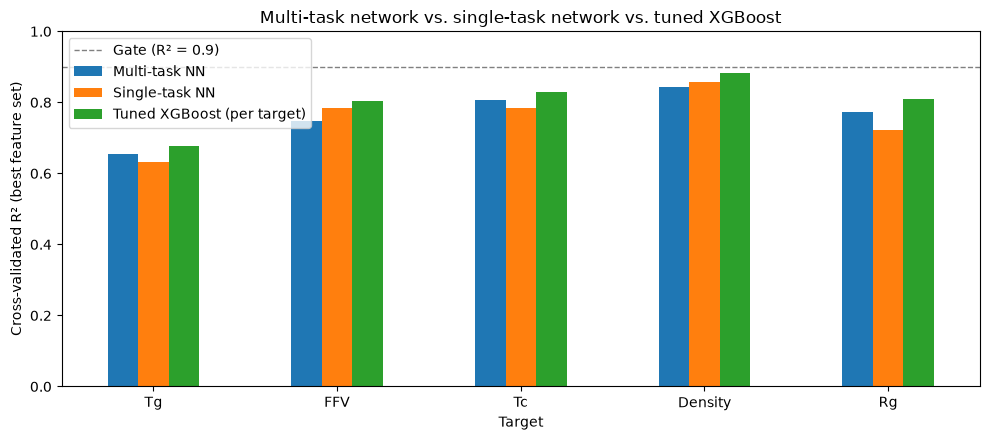

In [7]:
# Best tuned XGBoost per target (notebook 04, section 24)
xgboost_r2 = pd.Series({"Tg": 0.677, "FFV": 0.804, "Tc": 0.829, "Density": 0.883, "Rg": 0.809})

best_nn = (
    nn_results_df.groupby(["target", "model", "feature_set"])["R2"].mean()
    .groupby(["target", "model"]).max().unstack("model")
)
comparison = best_nn.assign(**{"Tuned XGBoost (per target)": xgboost_r2}).loc[target_columns]
display(comparison.round(3))

ax = comparison.plot(kind="bar", figsize=(10, 4.5), rot=0)
ax.axhline(0.9, color="grey", linestyle="--", linewidth=1, label="Gate (R² = 0.9)")
ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated R² (best feature set)")
ax.set_xlabel("Target")
ax.set_title("Multi-task network vs. single-task network vs. tuned XGBoost")
ax.legend()

plt.tight_layout()
plt.show()

#### Findings: multi-task network

Cross-validated R² (mean over 5 folds; best feature set per model):

| Target | Multi-task NN | Single-task NN | Tuned XGBoost (per target) |
|---|---:|---:|---:|
| Tg | 0.66 ± 0.08 | 0.63 | **0.68** |
| FFV | 0.75 | 0.78 | **0.80** |
| Tc | 0.81 ± 0.06 | 0.79 | **0.83** |
| Density | 0.84 | 0.86 | **0.88** |
| Rg | 0.77 ± 0.04 | 0.72 | **0.81** |

- **Sharing between targets helps the small targets.** With feature set B+,
  the multi-task network beats the single-task network for Tg (+0.03),
  Tc (+0.02) and Rg (+0.05). Tc, Density and Rg are mostly measured on the
  same polymers, so the network can learn from their relationships.
- **It costs FFV and Density.** FFV loses 0.07 compared with the single-task
  network, probably because the network now shares its capacity with four
  other targets and FFV no longer dominates the training.
- **The fingerprints hurt the networks** for most targets (e.g. Density
  0.84 → 0.66). With about 400–600 labels, 1,067 inputs lead to overfitting.
  Unlike XGBoost, the networks work better with the 43 descriptors.
- **Tuned XGBoost remains the best model for every target**, but the
  multi-task network comes close for Tg and Tc (differences within the
  fold-to-fold variation). The network was not tuned, whereas XGBoost
  was tuned with 30 settings per target.
- **One model for all five targets is feasible** with a moderate loss in
  accuracy, and without filling any missing values. No target reaches
  R² ≥ 0.9.

Possible next steps: a small, equal-budget tuning of the network,
and an ensemble that averages the multi-task network and XGBoost.

## 7. Ensemble: multi-task network + XGBoost

The network and XGBoost learn in very different ways, so they may make
different mistakes. An ensemble averages their predictions:

prediction = 0.5 × multi-task network + 0.5 × tuned XGBoost

The weights are fixed at 0.5 and not optimised, so the ensemble cannot
overfit the evaluation folds.

- **Multi-task network:** feature set B+, the same settings as in section 5.
- **XGBoost:** the best tuned model per target from notebook 04, section 24,
  with its feature set. The settings are copied exactly from that search.

Both models are trained on the same training folds and evaluated on the same
evaluation folds. Because the XGBoost settings were selected with these
folds, its scores (and those of the ensemble) are slightly optimistic;
the final check on the untouched validation subsets will show the true
performance.

In [8]:
from xgboost import XGBRegressor

# Best tuned XGBoost per target (notebook 04, section 24)
tuned_xgboost = {
    "Tg": ("B+ + D", dict(n_estimators=750, learning_rate=0.013339162948869679, max_depth=2,
                          min_child_weight=1, subsample=0.6550083776583973,
                          colsample_bytree=0.7394663949166917, reg_lambda=7.472397689332939)),
    "FFV": ("B+ + D", dict(n_estimators=1464, learning_rate=0.013815607382950859, max_depth=8,
                           min_child_weight=7, subsample=0.8034282764658811,
                           colsample_bytree=0.610167650697638, reg_lambda=0.4253162363790871)),
    "Tc": ("B+ + D", dict(n_estimators=708, learning_rate=0.013399060561509796, max_depth=5,
                          min_child_weight=7, subsample=0.6693458614031088,
                          colsample_bytree=0.7218455076693483, reg_lambda=4.638630972397279)),
    "Density": ("B+ + D", dict(n_estimators=1464, learning_rate=0.013815607382950859,
                               max_depth=8, min_child_weight=7, subsample=0.8034282764658811,
                               colsample_bytree=0.610167650697638,
                               reg_lambda=0.4253162363790871)),
    "Rg": ("B+", dict(n_estimators=1031, learning_rate=0.018187859051288217, max_depth=8,
                      min_child_weight=4, subsample=0.9439761626945282,
                      colsample_bytree=0.9140703845572055, reg_lambda=0.85807606199213)),
}

ensemble_rows = []
X_bplus = feature_sets["B+"].to_numpy(dtype=float)
start = time.time()

for fold in range(N_FOLDS):
    Y_fold = np.full_like(labels, np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y_fold[fit_rows, t] = labels[fit_rows, t]

    # Multi-task network on B+ (same seed as in section 5)
    has_label = ~np.isnan(Y_fold).all(axis=1)
    predict = fit_network(X_bplus[has_label], Y_fold[has_label], seed=RANDOM_STATE + fold)

    for t, target in enumerate(target_columns):
        rows = fold_rows[target][fold]
        fit_rows = np.flatnonzero(~np.isnan(Y_fold[:, t]))
        set_name, params = tuned_xgboost[target]
        X_set = feature_sets[set_name].to_numpy(dtype=float)

        xgboost = make_pipeline(
            SimpleImputer(strategy="median"),
            XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1),
        )
        xgboost.fit(X_set[fit_rows], Y_fold[fit_rows, t])

        y_true = labels[rows, t]
        predictions = {
            "Multi-task NN": predict(X_bplus[rows])[:, t],
            "Tuned XGBoost": xgboost.predict(X_set[rows]),
        }
        predictions["Ensemble (50/50)"] = (
            predictions["Multi-task NN"] + predictions["Tuned XGBoost"]
        ) / 2

        for model_name, y_pred in predictions.items():
            ensemble_rows.append({"target": target, "model": model_name, "fold": fold,
                                  "R2": r2_score(y_true, y_pred),
                                  "MAE": mean_absolute_error(y_true, y_pred)})

    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

ensemble_df = pd.DataFrame(ensemble_rows)

Fold 1 done (11 s)


Fold 2 done (25 s)


Fold 3 done (36 s)


Fold 4 done (48 s)


Fold 5 done (58 s)


model,Multi-task NN,Tuned XGBoost,Ensemble (50/50)
target,,,
Tg,0.656,0.675,0.694
FFV,0.718,0.801,0.784
Tc,0.806,0.829,0.833
Density,0.843,0.883,0.886
Rg,0.772,0.809,0.815


model,Multi-task NN,Tuned XGBoost,Ensemble (50/50)
target,,,
Tg,0.083,0.052,0.061
FFV,0.106,0.099,0.104
Tc,0.057,0.041,0.046
Density,0.051,0.055,0.037
Rg,0.038,0.045,0.031


,folds where the ensemble is best (of 5)
target,
Tg,3
FFV,1
Tc,4
Density,3
Rg,4


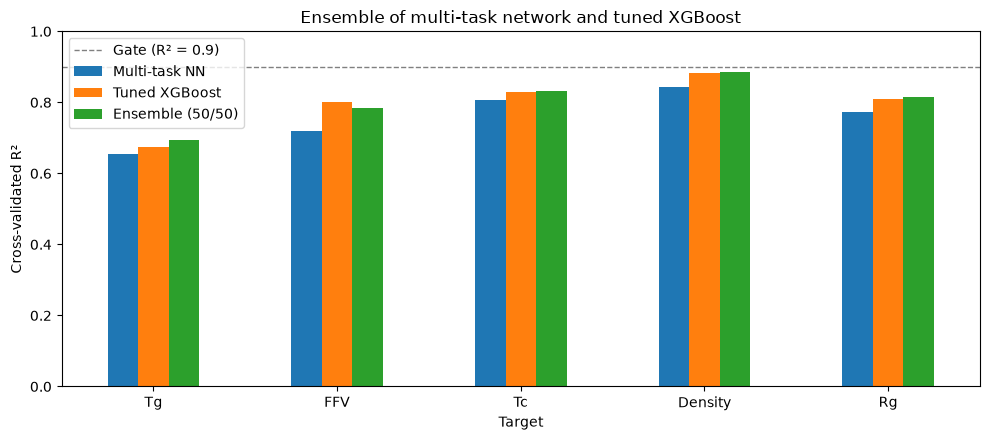

In [9]:
model_order = ["Multi-task NN", "Tuned XGBoost", "Ensemble (50/50)"]

ensemble_summary = ensemble_df.groupby(["target", "model"])["R2"].agg(["mean", "std"])
r2_table = ensemble_summary["mean"].unstack().loc[target_columns, model_order]
display(r2_table.round(3))
display(ensemble_summary["std"].unstack().loc[target_columns, model_order].round(3))

# Folds in which the ensemble beats the better of the two single models
fold_r2 = ensemble_df.pivot_table(index=["target", "fold"], columns="model", values="R2")
fold_r2["ensemble_best"] = fold_r2["Ensemble (50/50)"] > fold_r2[model_order[:2]].max(axis=1)
display(fold_r2.groupby("target")["ensemble_best"].sum().loc[target_columns]
        .rename("folds where the ensemble is best (of 5)").to_frame())

ax = r2_table.plot(kind="bar", figsize=(10, 4.5), rot=0)
ax.axhline(0.9, color="grey", linestyle="--", linewidth=1, label="Gate (R² = 0.9)")
ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated R²")
ax.set_xlabel("Target")
ax.set_title("Ensemble of multi-task network and tuned XGBoost")
ax.legend()

plt.tight_layout()
plt.show()

#### Findings: ensemble

| Target | Multi-task NN | Tuned XGBoost | Ensemble (50/50) | Folds where the ensemble is best |
|---|---:|---:|---:|---:|
| Tg | 0.66 | 0.68 | **0.69 ± 0.06** | 3 of 5 |
| FFV | 0.72 | **0.80 ± 0.10** | 0.78 | 1 of 5 |
| Tc | 0.81 | 0.83 | **0.83 ± 0.05** | 4 of 5 |
| Density | 0.84 | 0.88 | **0.89 ± 0.04** | 3 of 5 |
| Rg | 0.77 | 0.81 | **0.82 ± 0.03** | 4 of 5 |

- **The ensemble is slightly better than XGBoost for four targets**
  (Tg +0.02, Rg +0.01, Tc and Density +0.003 to +0.004). The gains are smaller
  than the fold-to-fold variation, but the ensemble wins in most folds,
  so the effect is consistent.
- For FFV, the ensemble is worse (−0.02), because the multi-task network
  is clearly weaker for FFV (0.72). XGBoost alone remains best for FFV.
- The ensemble also reduces the fold-to-fold spread for Density and Rg,
  so its predictions are more stable.
- The XGBoost scores reproduce section 24 of notebook 04 within 0.003.
- **No target reaches R² ≥ 0.9.** Density is closest (0.89).

**Candidate final models:** the ensemble for Tg, Tc, Density and Rg,
and tuned XGBoost for FFV. They will be checked once on the untouched
validation subsets.

## 8. Final evaluation on the validation subsets

All decisions are now made:

| Target | Final model |
|---|---|
| Tg, Tc, Density, Rg | Ensemble (50/50) of the multi-task network and tuned XGBoost |
| FFV | Tuned XGBoost |

Each model is trained once on the complete training subsets and evaluated
**once** on the validation subsets (20% of each target's labels), which
have not been used for any decision so far. No setting is changed after
this evaluation.

For reference, the same validation subsets are also scored with:

- the **median baseline** (always predicts the training median),
- the **starting model**: a default random forest on the nine original
  descriptors (feature set A, notebook 04, section 20).

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

valid_rows = {
    target: np.setdiff1d(train.index[train[target].notna()], train_rows[target])
    for target in target_columns
}
final_model = {target: "Ensemble (50/50)" for target in target_columns}
final_model["FFV"] = "Tuned XGBoost"

# Multi-task network trained on all training labels (validation labels masked)
Y_train = np.full_like(labels, np.nan)
for t, target in enumerate(target_columns):
    Y_train[train_rows[target], t] = labels[train_rows[target], t]

has_label = ~np.isnan(Y_train).all(axis=1)
predict_multitask = fit_network(X_bplus[has_label], Y_train[has_label], seed=RANDOM_STATE)

X_original = feature_sets["B+"][bplus_df.columns[:9]].to_numpy(dtype=float)

final_rows = []
final_predictions = {}

for t, target in enumerate(target_columns):
    fit_rows, rows = train_rows[target], valid_rows[target]
    y_fit, y_true = labels[fit_rows, t], labels[rows, t]

    set_name, params = tuned_xgboost[target]
    X_set = feature_sets[set_name].to_numpy(dtype=float)
    xgboost = make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1),
    ).fit(X_set[fit_rows], y_fit)

    starting_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    starting_model.fit(X_original[fit_rows], y_fit)

    predictions = {
        "Median baseline": DummyRegressor(strategy="median")
        .fit(X_original[fit_rows], y_fit).predict(X_original[rows]),
        "Starting model (RF, 9 descriptors)": starting_model.predict(X_original[rows]),
        "Multi-task NN": predict_multitask(X_bplus[rows])[:, t],
        "Tuned XGBoost": xgboost.predict(X_set[rows]),
    }
    predictions["Ensemble (50/50)"] = (
        predictions["Multi-task NN"] + predictions["Tuned XGBoost"]
    ) / 2
    final_predictions[target] = (y_true, predictions[final_model[target]])

    baseline_mae = mean_absolute_error(y_true, predictions["Median baseline"])
    for model_name, y_pred in predictions.items():
        final_rows.append({
            "target": target,
            "model": model_name,
            "R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "relative_MAE": mean_absolute_error(y_true, y_pred) / baseline_mae,
            "final": model_name == final_model[target],
        })

final_df = pd.DataFrame(final_rows)

display(final_df.pivot(index="target", columns="model", values="R2")
        .loc[target_columns, list(predictions)].round(3))

model,Median baseline,"Starting model (RF, 9 descriptors)",Multi-task NN,Tuned XGBoost,Ensemble (50/50)
target,,,,,
Tg,-0.024,0.372,0.460,0.527,0.534
FFV,-0.011,0.532,0.675,0.726,0.719
Tc,-0.033,0.644,0.826,0.795,0.820
Density,-0.074,0.349,0.744,0.819,0.798
Rg,-0.156,0.237,0.692,0.760,0.755


In [11]:
# Final models: validation results compared with cross-validation
cv_r2 = ensemble_df.groupby(["target", "model"])["R2"].mean()

final_summary = final_df[final_df["final"]].set_index("target").loc[target_columns]
final_summary["cv_R2"] = [cv_r2[(t, final_model[t])] for t in target_columns]
final_summary["error_reduction_%"] = (1 - final_summary["relative_MAE"]) * 100

starting = final_df[final_df["model"].str.startswith("Starting")].set_index("target")
final_summary["starting_model_R2"] = starting.loc[target_columns, "R2"]
final_summary["passes_gate"] = final_summary["R2"] >= 0.9

display(final_summary[["model", "starting_model_R2", "cv_R2", "R2", "MAE",
                       "error_reduction_%", "passes_gate"]].round(3))

,model,starting_model_R2,cv_R2,R2,MAE,error_reduction_%,passes_gate
target,,,,,,,
Tg,Ensemble (50/50),0.372,0.694,0.534,52.801,32.915,False
FFV,Tuned XGBoost,0.532,0.801,0.726,0.006,70.726,False
Tc,Ensemble (50/50),0.644,0.833,0.820,0.025,69.324,False
Density,Ensemble (50/50),0.349,0.886,0.798,0.028,73.478,False
Rg,Ensemble (50/50),0.237,0.815,0.755,1.457,62.287,False


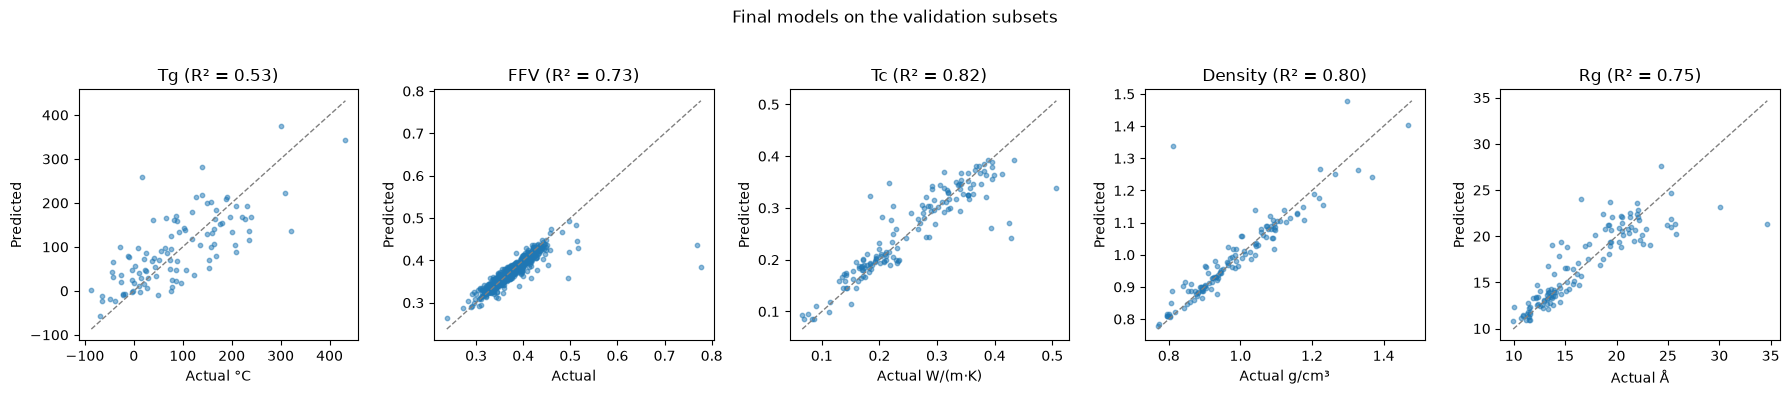

In [12]:
# Predicted vs. actual values of the final models on the validation subsets
units = {"Tg": "°C", "FFV": "", "Tc": "W/(m·K)", "Density": "g/cm³", "Rg": "Å"}
fig, axes = plt.subplots(1, len(target_columns), figsize=(18, 3.8))

for ax, target in zip(axes, target_columns):
    y_true, y_pred = final_predictions[target]
    ax.scatter(y_true, y_pred, s=10, alpha=0.5)

    limits = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(limits, limits, color="grey", linestyle="--", linewidth=1)

    ax.set_title(f"{target} (R² = {r2_score(y_true, y_pred):.2f})")
    ax.set_xlabel(f"Actual {units[target]}".strip())
    ax.set_ylabel("Predicted")

plt.suptitle("Final models on the validation subsets", y=1.03)
plt.tight_layout()
plt.show()

#### Findings: final evaluation

R² on the untouched validation subsets:

| Target | Starting model (RF, 9 descriptors) | Final model | Cross-validated R² | **Validation R²** | Error reduction vs. median |
|---|---:|---|---:|---:|---:|
| Tg | 0.37 | Ensemble | 0.69 | **0.53** | 33% |
| FFV | 0.53 | Tuned XGBoost | 0.80 | **0.73** | 71% |
| Tc | 0.64 | Ensemble | 0.83 | **0.82** | 69% |
| Density | 0.35 | Ensemble | 0.89 | **0.80** | 73% |
| Rg | 0.24 | Ensemble | 0.82 | **0.76** | 62% |

- **The final models are much better than the starting model for every target**
  on the same validation data: R² rises by 0.16 (Tg) to 0.52 (Rg).
- **The validation scores are lower than the cross-validated scores**,
  most strongly for Tg (0.69 → 0.53) and Density (0.89 → 0.80). Part of this is
  the expected optimism of cross-validation after model selection. A large part,
  however, comes from the validation subsets themselves: the untouched starting
  model also scores lower on them than in cross-validation (Tg 0.50 → 0.37,
  Rg 0.41 → 0.24, Density 0.45 → 0.35). With only 100–120 validation
  polymers per target (except FFV), a few difficult structures change R² noticeably.
- On the validation subsets, the ensemble is better than XGBoost alone for
  Tc and Tg, but slightly worse for Density and Rg. The differences are small,
  and, as agreed, no model is changed after this evaluation.
- **Goal of a 40% error reduction:** reached for FFV, Tc, Density and Rg
  (62–73%), **not reached for Tg (33%)**.
- **No target reaches R² ≥ 0.9.** Tc is closest (0.82).

**Conclusion.** Chemistry-motivated features gave the largest improvement;
tuning, fingerprints, the multi-task network and the ensemble each added
smaller gains. Tg remains the hardest property, with only 511 labels and the
weakest generalisation. The models are suitable for ranking and screening
candidate polymers, not for replacing simulations or measurements.

## 9. Evaluation with MAE

The coach clarified that R² ≥ 0.9 is not the right criterion and suggested
the **mean absolute error (MAE)** instead. MAE is the average distance
between prediction and true value, in the unit of the property
(e.g. °C for Tg), so it is easy to interpret for a chemist.

This section reports all results as MAE. No model is retrained or changed:

- **Cross-validation:** the fold predictions from section 7.
- **Validation subsets:** the one-time final evaluation from section 8.

To make the MAE comparable across properties, it is also shown

- as **error reduction** compared with the median baseline
  (1 − MAE / baseline MAE), and
- relative to the **typical spread** of the property
  (MAE divided by the standard deviation of the true values).

In [13]:
units = {"Tg": "°C", "FFV": "–", "Tc": "W/(m·K)", "Density": "g/cm³", "Rg": "Å"}

# Median baseline per fold, for the error reduction in cross-validation
cv_baseline_rows = []
for t, target in enumerate(target_columns):
    for fold in range(N_FOLDS):
        rows = fold_rows[target][fold]
        fit_rows = np.setdiff1d(train_rows[target], rows)
        median = np.median(labels[fit_rows, t])
        cv_baseline_rows.append({"target": target, "fold": fold,
                                 "baseline_MAE": np.mean(np.abs(labels[rows, t] - median))})
cv_baseline = pd.DataFrame(cv_baseline_rows).groupby("target")["baseline_MAE"].mean()

cv_mae = ensemble_df.groupby(["target", "model"])["MAE"].agg(["mean", "std"])
cv_mae_table = cv_mae["mean"].unstack().loc[target_columns, model_order]

cv_mae_summary = cv_mae_table.copy()
cv_mae_summary.insert(0, "Median baseline", cv_baseline.loc[target_columns])
cv_mae_summary["lowest MAE"] = cv_mae_table.idxmin(axis=1)
cv_mae_summary["unit"] = pd.Series(units)

print("Cross-validated MAE (mean over 5 folds)")
display(cv_mae_summary.round(4))

print("Cross-validated error reduction vs. median baseline (%)")
display(((1 - cv_mae_table.div(cv_baseline, axis=0)) * 100).loc[target_columns].round(1))

Cross-validated MAE (mean over 5 folds)


model,Median baseline,Multi-task NN,Tuned XGBoost,Ensemble (50/50),lowest MAE,unit
target,,,,,,
Tg,88.5952,50.4829,49.3249,47.2017,Ensemble (50/50),°C
FFV,0.0206,0.0088,0.0063,0.0070,Tuned XGBoost,–
Tc,0.0754,0.0271,0.0252,0.0250,Ensemble (50/50),W/(m·K)
Density,0.1045,0.0316,0.0286,0.0276,Ensemble (50/50),g/cm³
Rg,3.9069,1.4338,1.3656,1.3041,Ensemble (50/50),Å


Cross-validated error reduction vs. median baseline (%)


model,Multi-task NN,Tuned XGBoost,Ensemble (50/50)
target,,,
Tg,43.0,44.3,46.7
FFV,57.3,69.4,66.2
Tc,64.0,66.6,66.8
Density,69.8,72.6,73.6
Rg,63.3,65.0,66.6


In [14]:
# Validation subsets: MAE of all models from section 8
valid_mae = final_df.pivot(index="target", columns="model", values="MAE").loc[
    target_columns, list(predictions)
]
valid_std = pd.Series({t: final_predictions[t][0].std() for t in target_columns})

final_mae = final_df[final_df["final"]].set_index("target").loc[target_columns]
final_mae_summary = pd.DataFrame({
    "final_model": final_mae["model"],
    "unit": pd.Series(units),
    "baseline_MAE": valid_mae["Median baseline"],
    "starting_model_MAE": valid_mae["Starting model (RF, 9 descriptors)"],
    "final_MAE": final_mae["MAE"],
    "error_reduction_%": (1 - final_mae["relative_MAE"]) * 100,
    "MAE_per_std": final_mae["MAE"] / valid_std,
}).loc[target_columns]

print("MAE of all models on the validation subsets")
display(valid_mae.round(4))
print("Final models on the validation subsets")
display(final_mae_summary.round(4))

MAE of all models on the validation subsets


model,Median baseline,"Starting model (RF, 9 descriptors)",Multi-task NN,Tuned XGBoost,Ensemble (50/50)
target,,,,,
Tg,78.7083,62.5781,55.0352,53.6190,52.8012
FFV,0.0214,0.0109,0.0083,0.0063,0.0067
Tc,0.0801,0.0393,0.0253,0.0263,0.0246
Density,0.1044,0.0661,0.0327,0.0272,0.0277
Rg,3.8640,2.8721,1.6510,1.5017,1.4572


Final models on the validation subsets


,final_model,unit,baseline_MAE,starting_model_MAE,final_MAE,error_reduction_%,MAE_per_std
Tg,Ensemble (50/50),°C,78.7083,62.5781,52.8012,32.9153,0.5404
FFV,Tuned XGBoost,–,0.0214,0.0109,0.0063,70.7256,0.1949
Tc,Ensemble (50/50),W/(m·K),0.0801,0.0393,0.0246,69.3244,0.2658
Density,Ensemble (50/50),g/cm³,0.1044,0.0661,0.0277,73.4784,0.2089
Rg,Ensemble (50/50),Å,3.8640,2.8721,1.4572,62.2867,0.3106


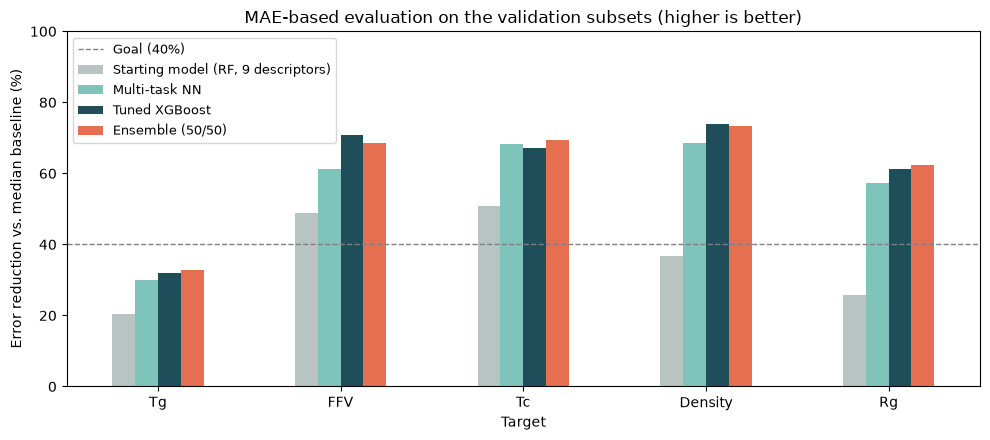

In [15]:
# Error reduction of every model on the validation subsets
reduction = (1 - final_df.pivot(index="target", columns="model", values="relative_MAE")) * 100
reduction = reduction.loc[target_columns, [m for m in predictions if m != "Median baseline"]]

ax = reduction.plot(kind="bar", figsize=(10, 4.5), rot=0,
                    color=["#b8c4c2", "#7fc4ba", "#1f4e5a", "#e76f51"])
ax.axhline(40, color="grey", linestyle="--", linewidth=1, label="Goal (40%)")
ax.set_ylim(0, 100)
ax.set_ylabel("Error reduction vs. median baseline (%)")
ax.set_xlabel("Target")
ax.set_title("MAE-based evaluation on the validation subsets (higher is better)")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [16]:
# Multi-task vs. single-task network (section 5) as error reduction vs. median baseline (%)
nn_mae = nn_results_df.groupby(["target", "feature_set", "model"])["MAE"].mean()
nn_reduction = (1 - nn_mae.div(cv_baseline, level="target")) * 100

print("Cross-validated error reduction of the networks (%)")
display(nn_reduction.unstack(["feature_set", "model"]).loc[target_columns].round(1))

print("Best feature set per network (%)")
display(nn_reduction.groupby(["target", "model"]).max().unstack().loc[target_columns].round(1))

Cross-validated error reduction of the networks (%)


feature_set            B+                       B+ + D               
model       Multi-task NN Single-task NN Multi-task NN Single-task NN
target                                                               
Tg                   43.0           40.2          30.8           33.0
FFV                  57.3           65.7          61.6           65.2
Tc                   64.0           62.3          58.2           54.0
Density              69.8           69.4          50.6           49.0
Rg                   63.3           57.0          57.0           54.8

Best feature set per network (%)


model,Multi-task NN,Single-task NN
target,,
Tg,43.0,40.2
FFV,61.6,65.7
Tc,64.0,62.3
Density,69.8,69.4
Rg,63.3,57.0


#### Findings: evaluation with MAE

**Model choice.** In cross-validation, the model with the lowest MAE is the ensemble
for Tg, Tc, Density and Rg, and tuned XGBoost for FFV. This is exactly the choice
made with R², so the final models do not change.

**Final models on the validation subsets:**

| Target | Unit | Median baseline | Starting model | **Final model** | Error reduction | MAE / std |
|---|---|---:|---:|---:|---:|---:|
| Tg | °C | 78.7 | 62.6 | **52.8** | 33% | 0.54 |
| FFV | – | 0.0214 | 0.0109 | **0.0063** | 71% | 0.19 |
| Tc | W/(m·K) | 0.080 | 0.039 | **0.025** | 69% | 0.27 |
| Density | g/cm³ | 0.104 | 0.066 | **0.028** | 73% | 0.21 |
| Rg | Å | 3.86 | 2.87 | **1.46** | 62% | 0.31 |

- **In absolute terms:** the final models predict Density within about ±0.03 g/cm³
  (about 3% of a typical value), FFV within ±0.006, Tc within ±0.025 W/(m·K),
  Rg within ±1.5 Å and Tg within about ±53 °C on average.
- **Compared with the starting model**, the MAE falls by 16% (Tg) to 58% (Density).
- **MAE / std** shows how large the error is compared with the typical spread of
  the property: about 0.2–0.3 for FFV, Tc, Density and Rg, but 0.54 for Tg.
  Tg remains the weakest property.
- In cross-validation, all five final models reach the 40% error-reduction goal
  (Tg 47%). On the validation subsets, Tg reaches only 33%, as already seen with R².
- On the validation subsets, XGBoost alone has a slightly lower MAE than the ensemble
  for Density (0.0272 vs. 0.0277). The difference is tiny, and the choice was made
  before this evaluation, so it is kept.
- Limitation: the tuning in notebook 04 (section 24) selected settings by R².
  Selecting by MAE could choose slightly different settings; this was not repeated.